# What is DropOuts

Deep Learning-এর মধ্যে Dropout হলো একটি Regularization Technique, যেটি Neural Network-কে Overfitting থেকে রক্ষা করতে সাহায্য করে। যেখানে Neural Network training চলাকালীন randomly কিছু neurons-কে সাময়িকভাবে inactive বা বন্ধ করে দেওয়া হয়।

অর্থাৎ, Training-এর সময় প্রতিটি iteration বা batch-এ কিছু neuron randomly বাদ দেওয়া হয়, যাতে Network নির্দিষ্ট কিছু neuron's ওপর অতিরিক্ত নির্ভরশীল না হয়ে পড়ে।

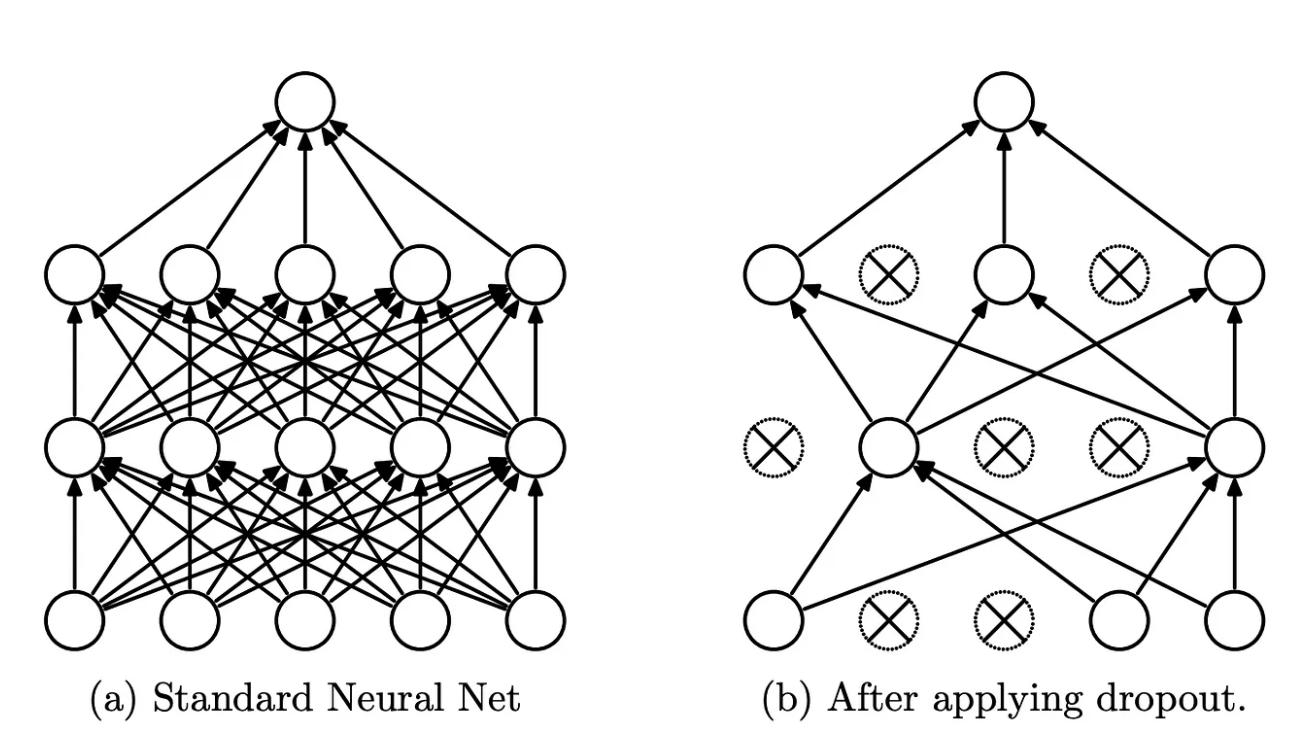

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [3]:
X_train = np.linspace(-1,1,20)

In [4]:
y_train = np.array([-0.6561, -0.3099, -0.59035, -0.50855, -0.285,
-0.2443, -0.02445, 0.00135, -0.2006, 0.07475,
-0.1422, 0.06515, 0.5524, 0.23115,
0.15265, 0.3521, 0.28415, 0.20835, 0.4211, 0.60485])

In [5]:
X_test = np.linspace(-1,1,20)

In [6]:
y_test =  np.array([-0.69415, -0.451, -0.43005, -0.4484, -0.1475, 
-0.5019, -0.28055, 0.24595, -0.21425, -0.0286, 0.23415, 0.46575, 
0.07955, 0.3639, 0.1973, 0.0719, 0.5536, 0.3365, 0.50705,
0.33435])

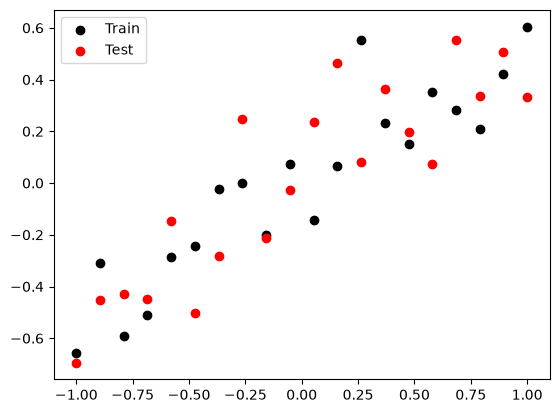

In [7]:
plt.scatter(X_train, y_train, c='black', label='Train')
plt.scatter(X_test, y_test, c='red', label='Test')
plt.legend()
plt.show()

# Regresion model

In [8]:
model = Sequential()
model.add(Input(shape=(1,)))
model.add(Dense(128,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dense(1,activation='linear'))

In [9]:
adam = Adam(learning_rate=0.01)
model.compile(loss='mse',optimizer=adam, metrics=['mse'])

history = model.fit(X_train,y_train, validation_data=(X_test,y_test), epochs=500, verbose=False)

# Evaluate the model

In [10]:
_, train_mse = model.evaluate(X_train,y_train, verbose=0)
_, test_mse = model.evaluate(X_test,y_test, verbose=0)
print(f'Train: {train_mse}, Test: {test_mse}')

Train: 0.0035642303992062807, Test: 0.05547682195901871


In [11]:
y_pred = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


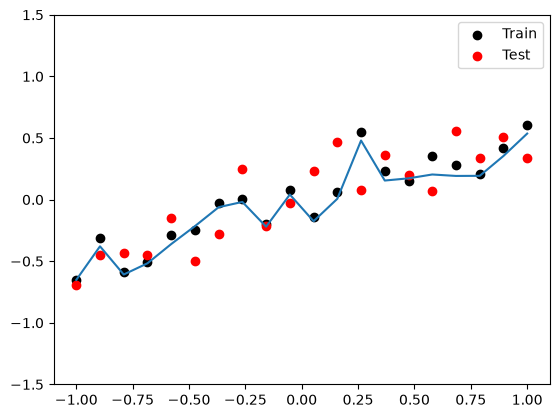

In [12]:
plt.figure()
plt.scatter(X_train,y_train, c='black', label = 'Train')
plt.scatter(X_test,y_test, c='red', label = 'Test')
plt.plot(X_test, y_pred)
plt.legend()
plt.ylim((-1.5,1.5))
plt.show()

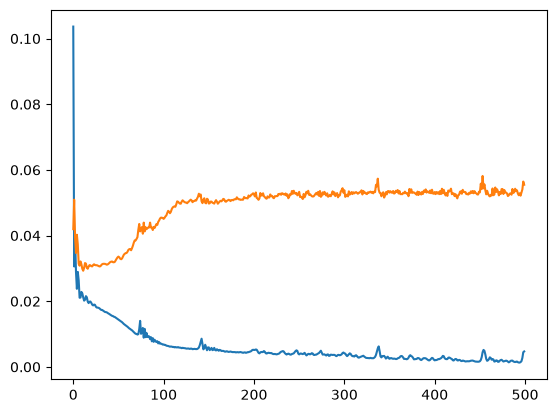

In [13]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

# DropOut Model

In [14]:
model = Sequential()
model.add(Input(shape=(1,)))

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(1,activation='linear'))
adam = Adam(learning_rate=0.01)
model.compile(loss='mse', optimizer=adam, metrics=['mse'])
history = model.fit(X_train,y_train, validation_data=(X_test,y_test), epochs=500, verbose=False)

# evaluate the model

In [15]:
_, train_mse = model.evaluate(X_train, y_train, verbose=0)
_, test_mse = model.evaluate(X_test, y_test, verbose=0)
print(f'Train: {train_mse}, Test: {test_mse}')

Train: 0.015389962121844292, Test: 0.034765053540468216


In [16]:
Y_pred = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


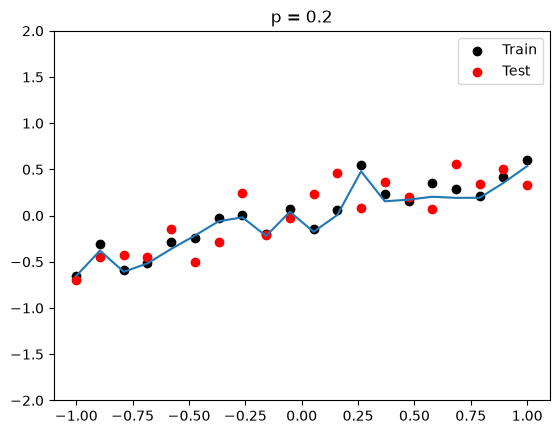

In [20]:
plt.figure()
plt.title('p = 0.2')
plt.scatter(X_train, y_train, c='black', label='Train')
plt.scatter(X_test, y_test, c='red', label='Test')
plt.plot(X_test,y_pred)
plt.legend()
plt.ylim((-2,2))
plt.show()

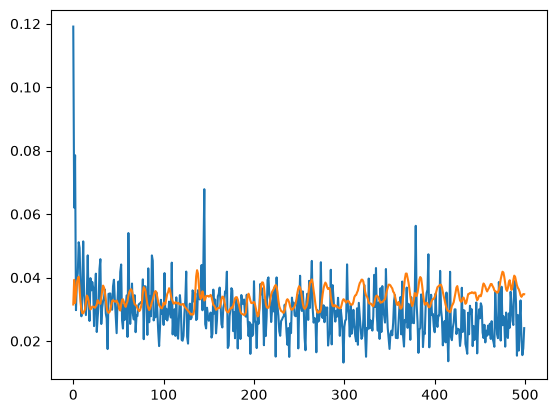

In [18]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])